<a href="https://colab.research.google.com/github/ankl-1/Machine-learning-/blob/main/Week-2-Multiple-Linear-Regression/Multivariable_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

X shape:(3, 4)
X:[[2104    5    1   45]
 [1416    3    2   40]
 [ 852    2    1   35]]
Y shape:(3,)
Y:[460 232 178]
w_init shape: (4,), b_init type: <class 'float'>
x_vec shape:(3, 4)
x_vec value:[[2104    5    1   45]
 [1416    3    2   40]
 [ 852    2    1   35]]
prediction is:[459.99999762 231.99999837 177.99999899]
The cost at optimal w is:1.5578904428966628e-12


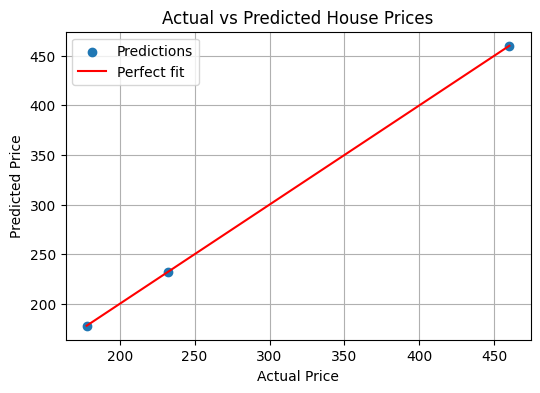

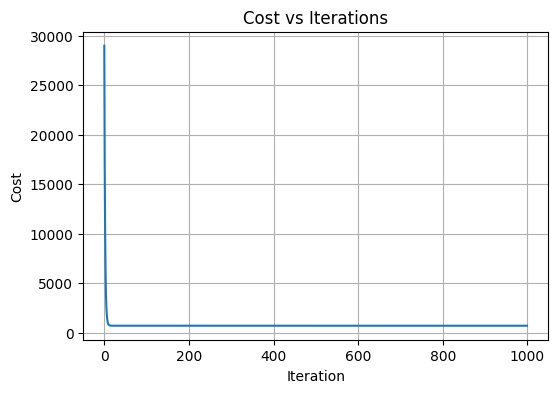

In [5]:
import numpy as np
import matplotlib.pyplot as plt
x_train=np.array([[2104, 5, 1, 45], [1416, 3, 2, 40], [852, 2, 1, 35]])
y_train=np.array([460, 232, 178])
print(f"X shape:{x_train.shape}\nX:{x_train}")
print(f"Y shape:{y_train.shape}\nY:{y_train}")
b_init = 785.1811367994083
w_init = np.array([ 0.39133535, 18.75376741, -53.36032453, -26.42131618])
print(f"w_init shape: {w_init.shape}, b_init type: {type(b_init)}")
def predict(x,w,b):
  p=np.dot(x,w)+b
  return p
x_vec=x_train[0:]
print(f"x_vec shape:{x_vec.shape}\nx_vec value:{x_vec}")
prediction=predict(x_vec,w_init,b_init)
print(f"prediction is:{prediction}")
def compute_cost(x,y,w,b):
  m=x.shape[0]
  cost=0
  for i in range(m):
    f_wb=np.dot(x[i],w)+b
    cost=cost+(f_wb-y[i])**2
  cost=cost/(2*m)
  return cost
cost=compute_cost(x_train,y_train,w_init,b_init)
print(f"The cost at optimal w is:{cost}")
def compute_gradient(x,y,w,b):
  m,n=x.shape
  dj_dw=np.zeros(n,)
  dj_db=0
  for i in range(m):
    err=(np.dot(x[i],w)+b)-y[i]
    for j in range(n):
      dj_dw[j]=dj_dw[j]+err*x[i,j]
    dj_db=dj_db+err
  dj_dw=dj_dw/m
  dj_db=dj_db/m
  return dj_dw,dj_db
def gradient_descent(x,y,w_in,b_in,alpha,ite,cost_function,gradient_function):
  j_his=[]
  w=w_in
  b=b_in
  for i in range(ite):
    dj_dw,dj_db=gradient_function(x,y,w,b)
    w=w-alpha*dj_dw
    b=b-alpha*dj_db
    if i<100000:
      j_his.append(cost_function(x,y,w,b))
  return w,b,j_his
y_pred = predict(x_train,w_init,b_init)
plt.figure(figsize=(6,4))
plt.scatter(y_train,y_pred,label="Predictions")
plt.plot([min(y_train),max(y_train)],[min(y_train),max(y_train)],color="red",label="Perfect fit")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.grid(True)
plt.show()
w_start=np.zeros(x_train.shape[1])
b_start=0.0
w_final,b_final,j_history=gradient_descent(x_train,y_train,w_start,b_start,1e-7,1000,compute_cost,compute_gradient)
plt.figure(figsize=(6,4))
plt.plot(j_history)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Cost vs Iterations")
plt.grid(True)
plt.show()
